# DeFi market overview: TVL, stablecoins, DEX volume and yields

This notebook explores **[DeFi Daily: TVL, Stablecoins, DEX & Yields](https://www.kaggle.com/datasets/danielaijdkx/defi-daily-tvl-stablecoins-dex-yields)**,
a dataset refreshed every day from the public DefiLlama API.

**Questions answered**
1. How has total value locked (TVL) in DeFi evolved since 2017?
2. Stablecoins: how much is in circulation, and how does that compare with DeFi TVL?
3. How active is trading on decentralized exchanges (DEXs)?
4. Where is the money today: which categories and blockchains? (and a double-counting trap)
5. What yields do stablecoin pools pay, and what does a high APY usually mean?
6. How to use the daily snapshot files, which grow by one day every day

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INK, INK2, GRID, SURFACE, MUTED = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb", "#c3c2b7"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "font.size": 10.5, "lines.linewidth": 2, "figure.figsize": (11, 4.6), "figure.dpi": 110,
    "legend.frameon": False, "axes.xmargin": 0.01,
})
billions = plt.FuncFormatter(lambda v, _: f"${v / 1e9:,.0f}B")


def find(name):
    """Locate a dataset file on Kaggle (/kaggle/input) or locally (DATA_ROOT)."""
    for root in ("/kaggle/input", os.environ.get("DATA_ROOT", "../input")):
        hits = glob.glob(f"{root}/**/{name}", recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(name)


def note(ax, x, y, text, dy=28, dx=0, ha="center"):
    """An annotation with a background, so it stays readable over lines."""
    ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center", fontsize=9, color=INK,
                bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec="none", alpha=0.9),
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))

In [2]:
tvl = pd.read_csv(find("defi_tvl_history.csv"), parse_dates=["date"]).set_index("date")["tvl_usd"]
stables = pd.read_csv(find("stablecoin_supply_history.csv"), parse_dates=["date"]).set_index("date")["total_circulating_usd"]
dex = pd.read_csv(find("dex_fees_history.csv"), parse_dates=["date"]).set_index("date")
protocols = pd.read_csv(find("protocols_latest.csv"))
chains = pd.read_csv(find("chains_latest.csv"))
pools = pd.read_csv(find("yield_pools_latest.csv"))
print(f"Data up to {tvl.index.max():%d %B %Y}")

Data up to 11 October 2026


## 1. Total value locked since 2017

TVL is the value of crypto assets deposited in DeFi protocols (lending pools, DEX liquidity,
staking and so on). This is DefiLlama's headline series, which avoids counting the same assets twice.

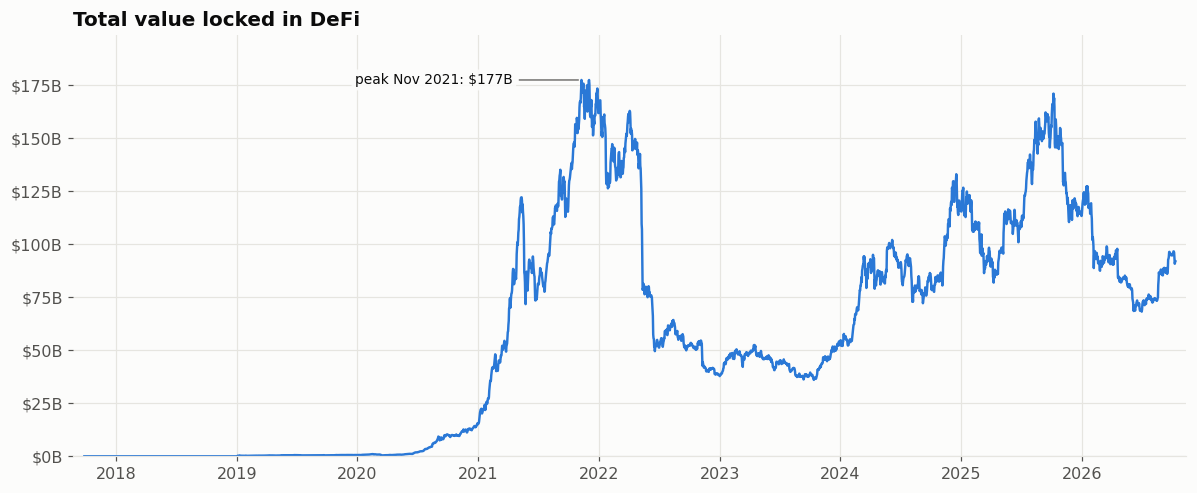

Today: $92B, which is 52% of the all-time high.


In [3]:
fig, ax = plt.subplots()
ax.plot(tvl.index, tvl, color=C[0], lw=1.6)
ax.yaxis.set_major_formatter(billions)
peak_day = tvl.idxmax()
note(ax, peak_day, tvl.max(), f"peak {peak_day:%b %Y}: ${tvl.max() / 1e9:,.0f}B", dy=0, dx=-45, ha="right")
ax.set_ylim(0, tvl.max() * 1.12)
ax.set_title("Total value locked in DeFi")
plt.tight_layout()
plt.show()
print(f"Today: ${tvl.iloc[-1] / 1e9:,.0f}B, which is {tvl.iloc[-1] / tvl.max():.0%} of the all-time high.")

TVL rose more than a hundredfold during the 2020-21 "DeFi summer" and bull market, then fell sharply
in 2022 (the collapse of the Terra/UST stablecoin in May and of the FTX exchange in November).
Because TVL is measured in dollars, it also moves with crypto prices, not only with deposits.

## 2. Stablecoins: the dollars of crypto

Stablecoins are tokens pegged to a currency, almost always the US dollar (USDT, USDC, ...).
Their supply is often read as the amount of "dry powder" available in crypto markets.

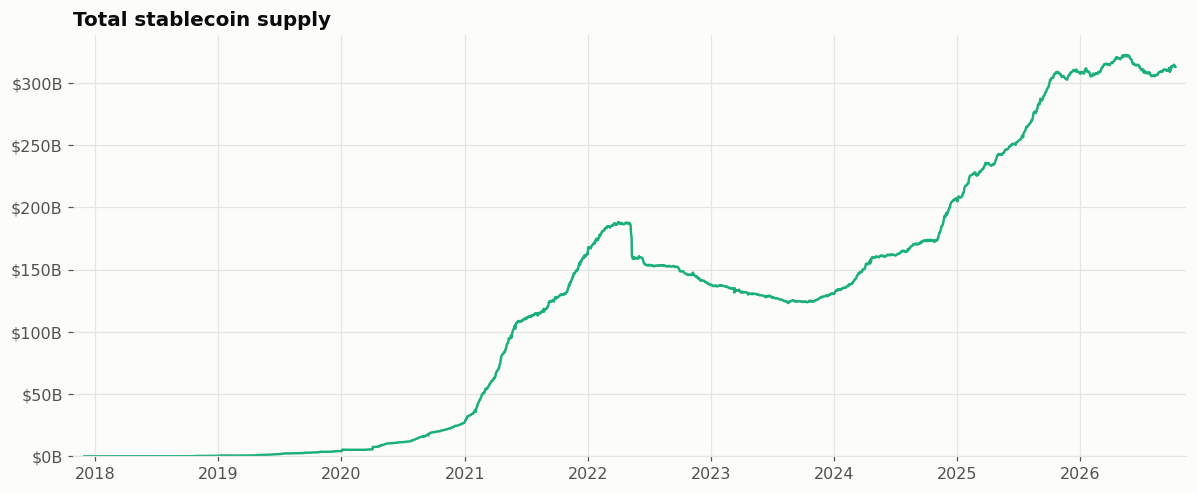

Stablecoin supply today: $313B
Share of total supply: USDT 59%, USDC 23%, USDS 2%, USDe 2%, DAI 2%, USD1 1%


In [4]:
fig, ax = plt.subplots()
ax.plot(stables.index, stables, color=C[2], lw=1.6)
ax.yaxis.set_major_formatter(billions)
ax.set_ylim(bottom=0)
ax.set_title("Total stablecoin supply")
plt.tight_layout()
plt.show()

top_stables = pd.read_csv(find("stablecoins_latest.csv"))
top_stables = top_stables[top_stables["peg_type"] == "peggedUSD"].nlargest(6, "circulating")
share = top_stables.set_index("symbol")["circulating"] / stables.iloc[-1] * 100
print(f"Stablecoin supply today: ${stables.iloc[-1] / 1e9:,.0f}B")
print("Share of total supply:", ", ".join(f"{s} {v:.0f}%" for s, v in share.round(0).items()))

Unlike TVL, the stablecoin supply has gone far beyond its 2022 level: more dollars sit on-chain
than ever, even though less value is locked in DeFi protocols. Two different charts are used on
purpose: the two series have different meanings and scales, and a shared double y-axis would
suggest a relationship the data doesn't show.

## 3. Trading activity on decentralized exchanges

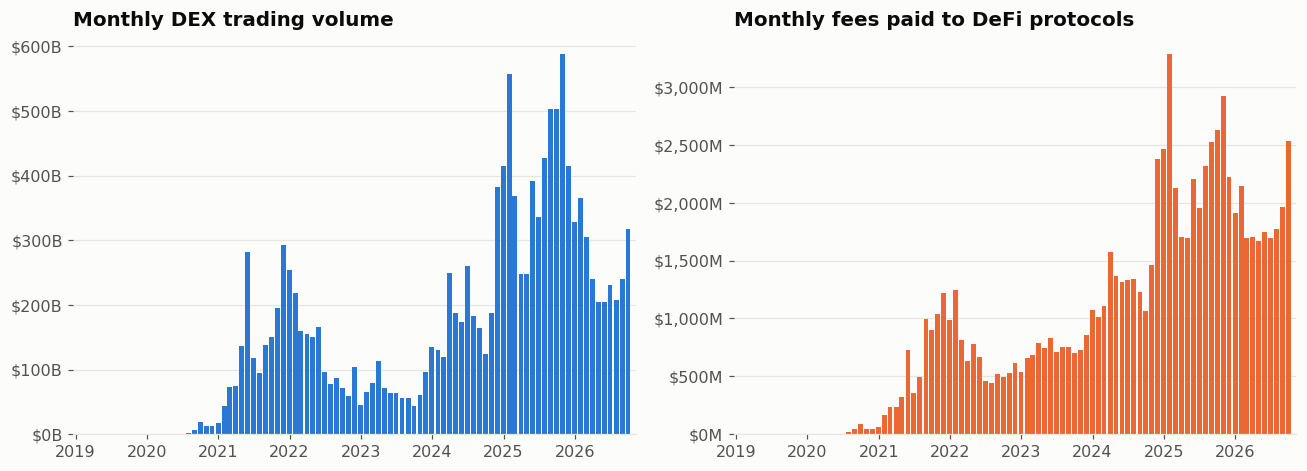

In [5]:
monthly = dex.resample("ME").sum(min_count=1).loc["2019":]
monthly = monthly.iloc[:-1]  # drop the current, incomplete month

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].bar(monthly.index, monthly["dex_volume_usd"], width=25, color=C[0])
axes[0].yaxis.set_major_formatter(billions)
axes[0].set_title("Monthly DEX trading volume")
axes[1].bar(monthly.index, monthly["fees_usd"], width=25, color=C[1])
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1e6:,.0f}M"))
axes[1].set_title("Monthly fees paid to DeFi protocols")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 4. Where is the money today?

`protocols_latest.csv` lists every protocol with its TVL, category and chains. It also includes
centralized exchanges (category `CEX`), which hold far more than DeFi itself, so filter them out.

**The double-counting trap:** adding up protocol TVLs gives a much bigger number than the headline
TVL in section 1, because the same assets are counted in several protocols (for example, ETH staked
with Lido, then the stETH token deposited in a lending protocol, then bridged to another chain).

Sum of protocol TVLs (excluding CEX): $281B
Headline DeFi TVL:                    $92B
-> use the sum only to compare categories, never as a market total.


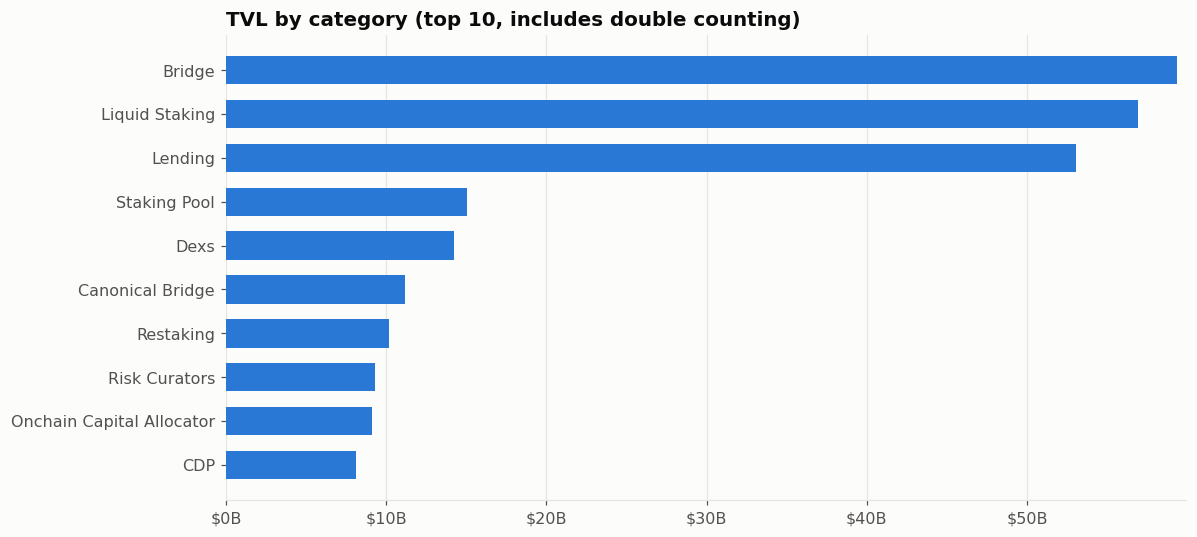

,name,category,primary_chain,TVL ($B),change_7d_pct
857,Lido,Liquid Staking,Multi-Chain,24.3,-8.519009
618,Aave V3,Lending,Multi-Chain,17.4,-4.475562
5277,SSV Network,Staking Pool,Ethereum,13.1,-7.310803
3912,LayerZero V2,Bridge,Multi-Chain,11.6,-1.881530
3075,Morpho Blue,Lending,Multi-Chain,11.2,-0.653081
1047,WBTC,Bridge,Bitcoin,9.7,-2.131888
1971,Binance staked ETH,Liquid Staking,Multi-Chain,9.3,-7.058534
4798,Coinbase Bridge,Bridge,Multi-Chain,8.1,-3.621571
3548,Hyperliquid Bridge,Bridge,Multi-Chain,7.0,-2.584823
2162,EigenCloud,Restaking,Ethereum,6.5,-7.575831


In [6]:
defi = protocols[protocols["category"] != "CEX"]
print(f"Sum of protocol TVLs (excluding CEX): ${defi['tvl_usd'].sum() / 1e9:,.0f}B")
print(f"Headline DeFi TVL:                    ${tvl.iloc[-1] / 1e9:,.0f}B")
print("-> use the sum only to compare categories, never as a market total.")

by_category = defi.groupby("category")["tvl_usd"].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(by_category.index, by_category.values, color=C[0], height=0.65)
ax.xaxis.set_major_formatter(billions)
ax.set_title("TVL by category (top 10, includes double counting)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

defi.nlargest(10, "tvl_usd")[["name", "category", "primary_chain", "tvl_usd", "change_7d_pct"]].assign(
    tvl_usd=lambda d: (d["tvl_usd"] / 1e9).round(1)).rename(columns={"tvl_usd": "TVL ($B)"})

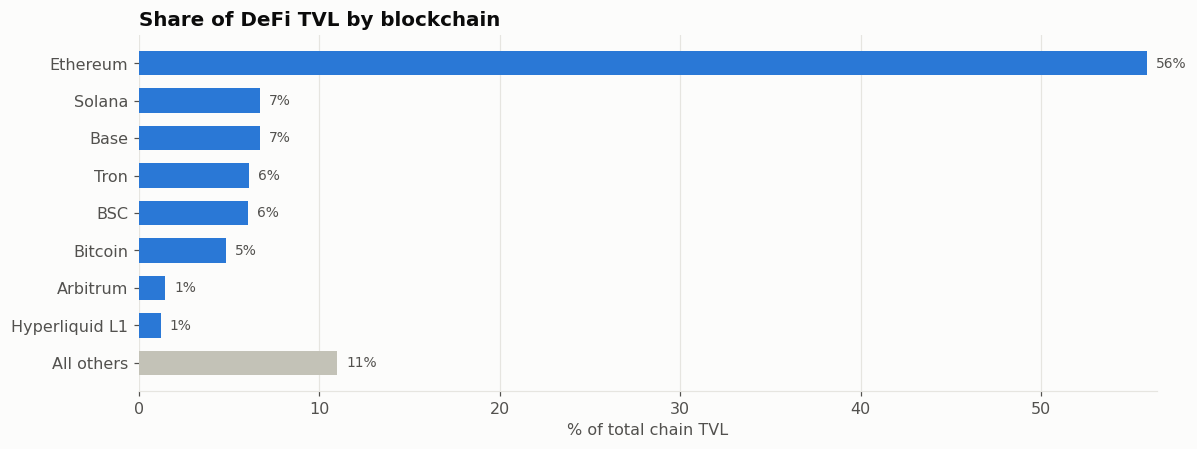

In [7]:
top = chains.nlargest(8, "tvl_usd").set_index("chain")["tvl_usd"]
rest = chains["tvl_usd"].sum() - top.sum()
chain_share = pd.concat([top, pd.Series({"All others": rest})]) / chains["tvl_usd"].sum() * 100
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.barh(chain_share.index[::-1], chain_share.values[::-1], color=[MUTED] + [C[0]] * 8, height=0.65)
for y, v in enumerate(chain_share.values[::-1]):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9, color=INK2)
ax.set_title("Share of DeFi TVL by blockchain")
ax.set_xlabel("% of total chain TVL")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Ethereum still holds the majority of DeFi value; no other chain comes close.

## 5. Yields: what do stablecoin pools pay?

`yield_pools_latest.csv` covers pools with at least $1M TVL. Stablecoin-only pools are the closest
thing DeFi has to a savings rate, because they don't depend on crypto prices.

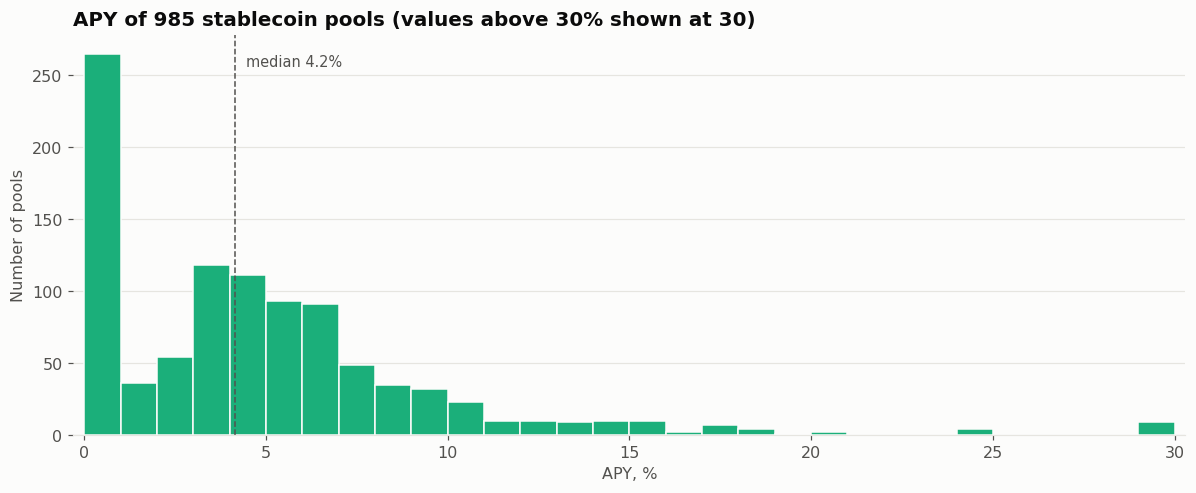

Median 4.2%, top 10% of pools above 10.0%


,pools,% of pools with reward tokens,median pool TVL ($M)
APY band,,,
0-5%,440,15.9,5.2
5-10%,301,46.5,4.9
10-20%,84,41.7,3.4
>20%,15,40.0,1.8


In [8]:
stable_pools = pools[pools["stablecoin"] == True]  # noqa: E712 - nullable boolean column
apy = stable_pools["apy"].clip(upper=30)

fig, ax = plt.subplots()
ax.hist(apy, bins=np.arange(0, 31, 1), color=C[2], edgecolor=SURFACE, linewidth=1)
med = stable_pools["apy"].median()
ax.axvline(med, color=INK2, ls="--", lw=1)
ax.text(med + 0.3, ax.get_ylim()[1] * 0.92, f"median {med:.1f}%", color=INK2, fontsize=9.5)
ax.set_title(f"APY of {len(stable_pools):,} stablecoin pools (values above 30% shown at 30)")
ax.set_xlabel("APY, %")
ax.set_ylabel("Number of pools")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Median {stable_pools['apy'].median():.1f}%, top 10% of pools above {stable_pools['apy'].quantile(0.9):.1f}%")
bands = pd.cut(stable_pools["apy"], [0, 5, 10, 20, 1e9], labels=["0-5%", "5-10%", "10-20%", ">20%"])
profile = stable_pools.groupby(bands, observed=True).agg(
    pools=("apy", "size"),
    with_reward_tokens=("apy_reward", lambda r: (r.fillna(0) > 0).mean() * 100),
    median_tvl_musd=("tvl_usd", lambda t: t.median() / 1e6),
)
profile.round(1).rename(columns={"with_reward_tokens": "% of pools with reward tokens",
                                 "median_tvl_musd": "median pool TVL ($M)"}).rename_axis("APY band")

Most stablecoin pools pay single-digit yields. Higher yields come with two warning signs:
- **Reward tokens:** pools paying more than 5% are much more likely to be boosted by incentives
  paid in the protocol's own token, whose price can fall.
- **Smaller pools:** the highest-yield pools hold less money, so they are usually newer, less
  battle-tested, and harder to exit in size.

A high APY is a question to investigate, not a free lunch.

## 6. Using the daily snapshot files

The `*_snapshots.parquet` files add one dated snapshot per day, so they grow into a panel you can't
get from the API directly. For example, the change in each protocol's TVL between the first and the
latest snapshot:

In [9]:
snap = pd.read_parquet(find("protocols_snapshots.parquet"))
days = sorted(snap["snapshot_date"].unique())
print(f"{len(days)} daily snapshots so far: {pd.Timestamp(days[0]):%Y-%m-%d} to {pd.Timestamp(days[-1]):%Y-%m-%d}")

first, last = days[0], days[-1]
panel = snap[snap["category"] != "CEX"].pivot_table(index="name", columns="snapshot_date", values="tvl_usd")
if len(days) > 1:
    change = panel[[first, last]].dropna()
    change = change[change[first] > 100e6]  # protocols above $100M, to avoid tiny-base noise
    change["change_%"] = (change[last] / change[first] - 1) * 100
    print("Biggest movers among protocols above $100M TVL:")
    display(change["change_%"].sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(1).to_frame())

2 daily snapshots so far: 2026-10-10 to 2026-10-11
Biggest movers among protocols above $100M TVL:


,change_%
name,
USDD,-7.6
Uniswap V2,-4.2
Cooler Loans,-2.3
Marinade Select,8.4
Hyperliquid Spot Orderbook,16.2
Starknet Bridge,45.6


As the snapshot history grows, this becomes a powerful panel for questions like: which categories
are gaining share, how quickly do new protocols grow, or how do yields react to market stress?

## Ideas for your own analysis

- Track stablecoin market share (USDT vs USDC vs others) over time with `stablecoins_snapshots.parquet`.
- Compare yields across chains for the same stablecoin.
- Forecast DEX volume, or relate it to TVL and stablecoin supply.

*Data: DefiLlama public API. If this was useful, an upvote on the notebook and the dataset helps
others find them.*